## 2.Feature engineering ***(ON GOING document when you finish)***

In [1]:
import pandas as pd
import numpy as np
from pathlib import Path 


In [2]:
DIR_NOTEBOOKS=Path.cwd()
DIR_ROOT=DIR_NOTEBOOKS.parent
DIR_DATA_RAW=DIR_ROOT/"data"/"raw"
DIR_DATA_PROCESSED=DIR_ROOT/"data"/"processed"
DIR_DATA_PROCESSED.mkdir(parents=True,exist_ok=True)
DIR_DATA_RAW.mkdir(parents=True,exist_ok=True)

In [3]:
X_train=pd.read_csv(DIR_DATA_PROCESSED/"train_imputed.csv",index_col="ID")
print(f"X_train_imputed shape is {X_train.shape}\n X_train columns are {list(X_train.columns)}")
display(X_train.head(5))

X_train_imputed shape is (843299, 60)
 X_train columns are ['r0', 'r1', 'r2', 'r3', 'r4', 'r5', 'r6', 'r7', 'r8', 'r9', 'r10', 'r11', 'r12', 'r13', 'r14', 'r15', 'r16', 'r17', 'r18', 'r19', 'r20', 'r21', 'r22', 'r23', 'r24', 'r25', 'r26', 'r27', 'r28', 'r29', 'r30', 'r31', 'r32', 'r33', 'r34', 'r35', 'r36', 'r37', 'r38', 'r39', 'r40', 'r41', 'r42', 'r43', 'r44', 'r45', 'r46', 'r47', 'r48', 'r49', 'r50', 'r51', 'r52', 'n_missing', 'n_obs', 'avg_sq_return', 'Realised_vol', 'equity', 'day', 'reod']


,r0,r1,r2,r3,r4,r5,r6,r7,r8,r9,...,r50,r51,r52,n_missing,n_obs,avg_sq_return,Realised_vol,equity,day,reod
ID,,,,,,,,,,,,,,,,,,,,,
0,0.00,0.00,0.00,0.00,0.00,0.00,0.00,-68.03,-34.25,0.00,...,0.00,0.00,0.00,29,24,1520.422917,191.023951,1488,249,0
1,-9.76,0.00,-12.21,46.44,34.08,0.00,41.24,12.08,-26.54,19.32,...,-19.38,9.71,26.68,0,53,351.657215,136.520447,107,272,0
2,49.85,0.00,0.00,-26.64,-23.66,-22.14,49.12,53.61,-4.70,-28.27,...,-6.39,7.99,15.96,0,53,570.906711,173.948428,1063,323,-1
3,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,...,0.00,0.00,0.00,39,14,9.594864,11.590000,513,302,0
4,-123.84,-115.18,-26.44,0.00,42.42,10.56,0.00,-47.57,21.28,-10.63,...,5.41,-32.47,43.43,0,53,1340.656189,266.561021,1465,123,-1


# feature i) long/short term volatility 

## HAR model .... 

- long short term vol 
- how to pick the treshold ? 3 options :
- A:
  - first window of openning (first 30 min)--> most informative 
  - last window (last 30 min )
- B : 
  - let correlation between r_i tell you where to cut 

- - ***Autocorrelation at lag k***

## autocorrelation( same vairbale at different time ): when ri goes up does ri+1 goes up or down ? 

##### /!\ since data is 0 filled we will use the raw data to compute correlation between lags, so that pearson correlation wouldn't be pushed toward 0 , and we will drop outliers so the pearson score will be accurate 

In [4]:
raw=pd.read_csv(DIR_DATA_RAW/"input_training.csv",index_col="ID")
bad_ids=X_train.index[X_train["Realised_vol"]>10000]
r_i=[f"r{i}" for i in range(53)]
print(raw.loc[bad_ids,r_i].abs().max(axis=1).sort_values(ascending=False))

ID
474460    4.310700e+08
358758    2.210600e+08
252237    1.640900e+08
232906    1.039000e+08
29665     7.516000e+07
704752    6.526000e+07
699094    6.461000e+07
275851    5.726000e+07
77299     5.485000e+07
689996    4.949000e+07
445714    4.821000e+07
434103    4.789000e+07
630830    3.798000e+07
361728    3.724000e+07
233499    3.713000e+07
690730    3.477000e+07
79511     3.147000e+07
53359     2.837000e+07
136130    2.490000e+07
639723    2.032000e+07
712950    1.685000e+07
281727    1.545000e+07
343531    1.309000e+07
515014    1.263000e+07
732119    4.540000e+06
836665    1.537000e+04
585884    9.967800e+03
793335    9.948130e+03
672786    9.937000e+03
dtype: float64


In [5]:
print((raw.loc[bad_ids,r_i].abs()>1000).sum(axis=1).value_counts())

1    25
2     4
Name: count, dtype: int64


In [6]:
raw.loc[bad_ids, r_i].abs().idxmax(axis=1).value_counts()

r0    23
r1     4
r3     1
r2     1
Name: count, dtype: int64

- /!\ all bad ids sit in the first four returns of the day so it's not random through the session /!\
- dropping the bad ids to compute correlation

In [7]:
X_raw=raw.drop(index=bad_ids)
X_raw.shape

(843270, 55)

### lag1 sign (up or down)

In [8]:
#2 columns for lag1 pairs table earlier and before
earlier= X_raw[r_i].iloc[:,:-1]
later= X_raw[r_i].iloc[:,1:]

pairs=pd.DataFrame({
    "earlier": earlier.to_numpy().ravel(),
    "later": later.to_numpy().ravel(),
})
pairs.shape

(43850040, 2)

In [9]:
#manual check
#X_raw[r_i].iloc[0].to_numpy()[:5]
#pairs.iloc[:5]
pairs_without_na=pairs.dropna().shape

- to see how many pairs pearson correlation is actually going to use 

In [10]:
correl=pairs["earlier"].corr(pairs["later"])
float(correl)

-0.005634047348680288

- this mathces weak form market efficiency: knowing the previous return don't allow to predict the next one 
- this tells us only about the direction of consecutive returns(i.e  if a window went up the next one isn't likely to move up (ie no momentum), and not more likely to move down (ie no mean reversal)), but it tells us nothing about the size(volatility), that we have found eda that's whwe would do the same with absolute value 

In [11]:
print(f"typical luck {1/np.sqrt(pairs_without_na[0])}")

typical luck 0.00016335392908807086


- NOISE LEVEL OF THE CORRELATION ESTIMATE : 1/SQRT(N)

### CONCLUSION : DIRECTION ( LAG1 ) ISN'T PREDICTABLE

## lag1 size (how big)/ correlation of abs(return): does agitation persist from one window to another 

In [12]:
earlier_abs=X_raw[r_i].iloc[:,:-1].abs()
later_abs=X_raw[r_i].iloc[:,1:].abs()

In [13]:
pairs_abs=pd.DataFrame({
    "earlier": earlier_abs.to_numpy().ravel(),
    "later": later_abs.to_numpy().ravel()
})
#pairs_abs.head(5)

In [14]:
pearson_abs=pairs_abs["earlier"].corr(pairs_abs["later"])
spearman_abs=pairs_abs["earlier"].corr(pairs_abs["later"],method="spearman")
print(f"pearson correlation abs: {pearson_abs}")
print(f"spearman correlation abs: {spearman_abs}")

pearson correlation abs: 0.22353374890759428
spearman correlation abs: 0.2307616833151362


- /!\ /!\ /!\  we have a clear positive correlation : VOLATILITY CLUSTERING IS REAL A BIG MOVE TENDS TO BE FOLLOWED BY A BIG MOVE /!\ /!\ /!\ 
- NOT DRIVEN BY EXTREM VALUES BECAUSE PEARSON AND SPEARMAN ARE CLOSE

## CONCLUSION: SIZE IS PREDICTABLE 

- BUT HOW FAR BACK WE NEED TO LOOK ? WE NEED TO COMPUTE LAG 1,...,20... ON ABSOLUTE RETURNS AND PLOT A CURVE 
    - FAST DECAY TO 0 MEANS THAT A SHORT WINDOW IS ENOUGH 
    - A SLOW DECAY TO 0 MEANS THAT LONG WINDOWS CARRIES INFORMATION TOO  

In [15]:
l=[]
for k in range(1,53):
    earlier_k=X_raw[r_i].iloc[:,:-k].abs()
    later_k=X_raw[r_i].iloc[:,k:].abs()
    pairs_k=pd.DataFrame({
        "earlier":earlier_k.to_numpy().ravel(),
        "later":later_k.to_numpy().ravel()  
    })
    corr_k=pairs_k["earlier"].corr(pairs_k["later"])
    l.append((k,corr_k))
acf=pd.DataFrame(l,columns=["lag","corr"])

<Axes: xlabel='lag'>

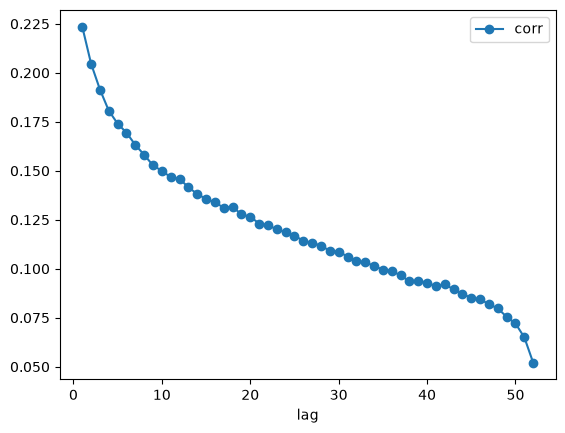

In [16]:
acf.plot(x="lag",y="corr",marker="o")

- the correlation still 0.1 at lag 30 (which is 2.5 hours later), if Volatility has a short memory it will decay after few lags --> we conclude tha tmemory is long.... 
  ## /!\/!\  but we should be carfule and look which effect creats this correlation : /!\ /!\ 
    - Option 1 : between rows ( stocks ), some stocks are agitated and others are always calm.If we pool all rows, a wild row have large values everywhere and a calm row has small values , that's can creat a positve correlation without any real VOL clustering /!\
    - Option2: real clustering i.a a Burst at 10:00 makes agitation at 10:05 

In [17]:
abs_r=X_raw[r_i].abs()
row_mean=abs_r.mean(axis=1)
centered=abs_r.sub(row_mean,axis=0)
l2=[]
for k in range(1, 53):
    earlier_k=centered.iloc[:, :-k]
    later_k =centered.iloc[:, k:]
    pairs_k =pd.DataFrame({
        "earlier": earlier_k.to_numpy().ravel(),
        "later": later_k.to_numpy().ravel(),
    })
    l2.append((k, pairs_k["earlier"].corr(pairs_k["later"])))

acf_centered = pd.DataFrame(l2,columns=["lag", "corr"])

<Axes: xlabel='lag'>

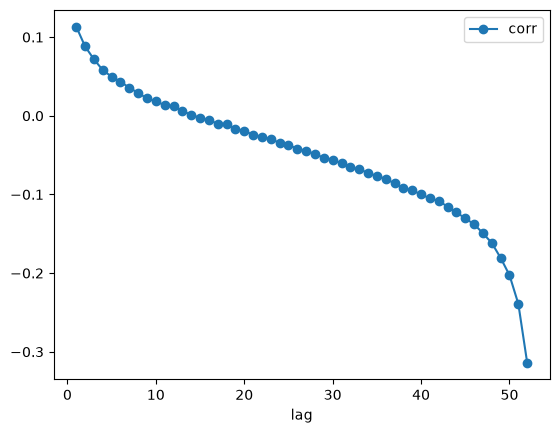

In [18]:
acf_centered.plot(x="lag",y="corr",marker="o")

- real within morning volatility clustring exists and fades at lag 13 (more than 1 hour)
- long lags the correlation goes negative due to one of those : 
    - centring forces compensation or 
    - time of the day profile (aka seaonality)

<Axes: >

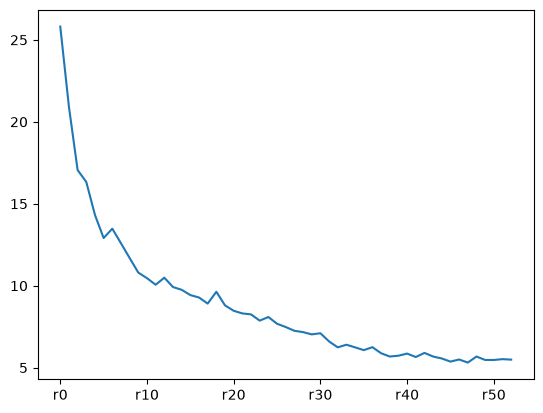

In [19]:
abs_r.median().plot()

- the open is 5 times more agitated than the closing : time of the day profile let's remove it with the volume and see 

In [20]:
profile = abs_r.median()
normalized = abs_r.div(profile, axis=1)
centered_norm = normalized.sub(normalized.mean(axis=1), axis=0)
centered_norm.mean(axis=1).abs().max()


np.float64(2.0024386189602825e-14)

<Axes: xlabel='lag'>

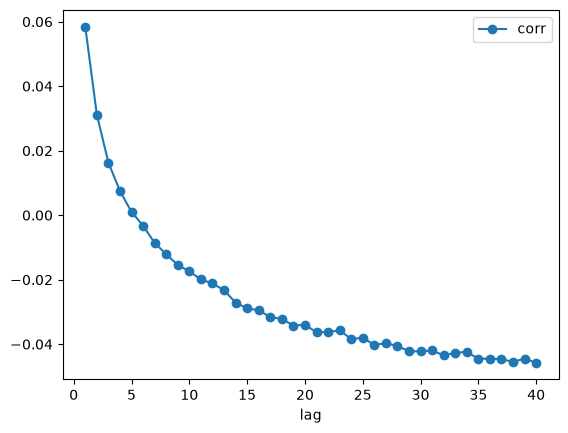

In [21]:

l4 = []
for k in range(1, 41):
    earlier_k = centered_norm.iloc[:, :-k]
    later_k = centered_norm.iloc[:, k:]
    pairs_k = pd.DataFrame({
        "earlier": earlier_k.to_numpy().ravel(),
        "later": later_k.to_numpy().ravel(),
    })
    l4.append((k, pairs_k["earlier"].corr(pairs_k["later"])))

acf_centered_norm = pd.DataFrame(l4, columns=["lag", "corr"])
acf_centered_norm.plot(x="lag", y="corr", marker="o")

- afer removing time of the day profile (i.e the size of the return depends on what time in the day it happens) and every row level, the correlation is 0.059 at lag 1 and attend 0 at lag 5 , beyond that it goes slightly negative & flattened arround -0.045
- ***Conclusion : real clustering exists but it's short***

### Autocorrelation findings

- Raw returns lag 1: -0.0056 -->  direction is not predictable.
- Absolute returns lag 1: +0.22 --> size is predictable(volatility clustering)
- Persistence over hours came from row level and time of day

| Curve | Lag 1 | Lag 40 | Contains |
|---|---|---|---|
| Raw \|r\| | 0.22 | 0.09 | level + time of day + clustering |
| Divided by median profile | 0.26 | 0.134 | level + clustering |
| Profile + row level removed | 0.058 | -0.045 | clustering only |

- Conclusion: real clustering is short (crosses 0 at 5 lags==25min)
- Windows:short = last 5 returns,long= full morning plus ratio short/long
- Normalize by the median profile first Final windows validated by GroupKFold